# AtmoSync: Micro-Climate Arbitrage Analytics

Standard supply-chain analytics rely on fixed transit times and regional weather forecasts.
They miss what actually spoils fresh produce: the **micro-climate inside one shipping
container**. A cooling unit that drifts a few degrees, a door seal that lets humidity spike,
or rough handling that bruises the fruit all change how fast the cargo loses quality, long
before it reaches the market.

This notebook builds the whole pipeline in one place and answers one question:

> **Which shipments should be rerouted to a closer secondary market before they lose their
> premium grade, and how much money does that decision protect?** (the *Spoilage Arbitrage*)

**Pipeline at a glance**

| Stage | Built here with | What it does |
|---|---|---|
| Streaming ingestion | `MiniTopic` / `MiniConsumer`: partitions, offsets, consumer commits | Carries IoT sensor events in micro-batches |
| Data warehouse | A SQLite file, `atmosync.db` | Stores raw sensor events, commodity prices and container data |
| Transformation | Layered SQL models (staging, intermediate, facts, marts) | Cleans the stream, models spoilage curves, computes arbitrage |
| Visualisation | A matplotlib dashboard rebuilt from the mart tables | KPIs, alerts and reroute decisions |

> **Data note:** sensors, prices, cargo and routes are simulated, with realistic noise and
> faults injected on purpose. The results demonstrate the method, not real market findings.

**To run:** `pip install pandas numpy matplotlib jupyter`, then *Kernel, Restart & Run All*.
Nothing else is needed. The notebook creates its own database file next to itself.

## 1. Setup and configuration

In [1]:
import os
import math
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

SEED = 7
rng = np.random.default_rng(SEED)

DB_PATH = "atmosync.db"
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)            # fresh warehouse on every run
conn = sqlite3.connect(DB_PATH)

# Window functions (used heavily below) need SQLite 3.25 or newer
ver = tuple(int(x) for x in sqlite3.sqlite_version.split("."))
assert ver >= (3, 25), f"SQLite {sqlite3.sqlite_version} is too old for window functions"

VOYAGE_START = pd.Timestamp("2026-10-01 00:00:00")
STREAM_HOURS = 144            # replay the first 6 days at sea, then "go live"
READINGS_PER_HOUR = 4         # one reading every 15 minutes per container
BATCH_HOURS = 3               # micro-batch size (how often the pipeline refreshes)

QUALITY_THRESHOLD = 70        # below this the cargo loses its premium grade
MIN_ARBITRAGE_USD = 2000      # only recommend a reroute if it nets at least this much

def usd(v):
    return f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"

print("SQLite version:", sqlite3.sqlite_version)

SQLite version: 3.45.1


## 2. Reference data: commodities, containers and the quality-to-price curve

**Spoilage model.** Each commodity loses quality (a 0 to 100 score) at a rate that depends on
what the sensors report:

```
loss_rate (points/hour) = base_rate x Q10 ^ ((T - T_optimal) / 10)       temperature effect
                          x (1 + k_h x humidity_outside_band_%)           humidity effect
                          + k_v x max(0, vibration - threshold)           bruising from rough handling
```

The `Q10` term is the standard rule that respiration (and so spoilage) speeds up by a factor of
`Q10` for every 10 C above the optimal storage temperature. Quality starts at 100 on departure
and falls as losses accumulate.

**Price curve.** Buyers pay less as quality drops. We interpolate a multiplier between a few
grade points, so a shipment that falls below the threshold loses value sharply.

In [2]:
# ---- seed table: spoilage parameters per commodity (like a dbt seed) ----
commodity_params = pd.DataFrame([
    # commodity, optimal temp C, RH band low/high %, base loss pts/hr, Q10, humidity k, vibration threshold g, vibration k
    ("Avocado", 5.5, 85, 95, 0.060, 2.5, 0.30, 1.0, 0.15),
    ("Banana", 13.5, 90, 95, 0.070, 2.2, 0.30, 1.0, 0.15),
    ("Mango", 12.0, 85, 90, 0.080, 2.4, 0.30, 1.0, 0.15),
], columns=["commodity", "opt_temp_c", "opt_rh_lo", "opt_rh_hi", "base_loss_pts_hr",
            "q10", "hum_k", "vib_thresh_g", "vib_k"])
commodity_params.to_sql("ref_commodity_params", conn, index=False)
P = commodity_params.set_index("commodity").to_dict("index")

# ---- the six containers we monitor ----
containers = pd.DataFrame([
    # id, commodity, cargo kg, origin, primary market, secondary market, primary ETA h, secondary ETA h, reroute cost USD
    ("A", "Avocado", 20000, "Veracruz",        "Rotterdam", "Valencia",  336, 216, 3000),
    ("B", "Banana",  20000, "Guayaquil",       "Hamburg",   "Lisbon",    312, 228, 3500),
    ("C", "Mango",   18000, "Callao",          "Antwerp",   "Algeciras", 288, 204, 3500),
    ("D", "Avocado", 20000, "Lazaro Cardenas", "Rotterdam", "Valencia",  336, 216, 3000),
    ("E", "Banana",  20000, "Santa Marta",     "Hamburg",   "Lisbon",    324, 234, 3500),
    ("F", "Mango",   18000, "Paita",           "Antwerp",   "Algeciras", 300, 222, 3500),
], columns=["container_id", "commodity", "cargo_kg", "origin", "primary_market", "secondary_market",
            "primary_eta_hr", "secondary_eta_hr", "reroute_cost_usd"])
containers["departure_ts"] = VOYAGE_START.strftime("%Y-%m-%d %H:%M:%S")
containers.to_sql("raw_containers", conn, index=False)

# ---- quality -> price multiplier (used as a SQL function, like a warehouse UDF) ----
QUALITY_PTS    = [0,    40,   60,   80,   90,   100]
PRICE_MULT_PTS = [0.05, 0.15, 0.45, 0.80, 0.95, 1.00]

def price_mult(q):
    return None if q is None else float(np.interp(q, QUALITY_PTS, PRICE_MULT_PTS))

def pypow(a, b):
    return None if a is None or b is None else float(a) ** float(b)

conn.create_function("PRICE_MULT", 1, price_mult)
conn.create_function("PYPOW", 2, pypow)

display(containers.drop(columns="departure_ts"))
print("\nPrice multiplier by quality:")
print(pd.DataFrame({"quality": QUALITY_PTS, "price_multiplier": PRICE_MULT_PTS}).T.to_string(header=False))

,container_id,commodity,cargo_kg,origin,primary_market,secondary_market,primary_eta_hr,secondary_eta_hr,reroute_cost_usd
0,A,Avocado,20000,Veracruz,Rotterdam,Valencia,336,216,3000
1,B,Banana,20000,Guayaquil,Hamburg,Lisbon,312,228,3500
2,C,Mango,18000,Callao,Antwerp,Algeciras,288,204,3500
3,D,Avocado,20000,Lazaro Cardenas,Rotterdam,Valencia,336,216,3000
4,E,Banana,20000,Santa Marta,Hamburg,Lisbon,324,234,3500
5,F,Mango,18000,Paita,Antwerp,Algeciras,300,222,3500



Price multiplier by quality:
quality           0.00  40.00  60.00  80.0  90.00  100.0
price_multiplier  0.05   0.15   0.45   0.8   0.95    1.0


## 3. Historical commodity prices

Ninety days of daily wholesale prices per commodity and market. Each series follows a base
price with a slow seasonal swing and day-to-day noise that carries over from one day to the next.
Secondary markets are priced a little lower than primary markets, which is why rerouting only
pays off when spoilage is bad enough.

In [3]:
MARKET_BASE = {
    ("Avocado", "Rotterdam"): 4.60, ("Avocado", "Valencia"): 4.10,
    ("Banana",  "Hamburg"):   1.35, ("Banana",  "Lisbon"):   1.22,
    ("Mango",   "Antwerp"):   2.90, ("Mango",   "Algeciras"): 2.62,
}

last_price_day = (VOYAGE_START + pd.Timedelta(hours=STREAM_HOURS - 1)).normalize()
price_days = pd.date_range(end=last_price_day, periods=90, freq="D")

rows = []
for (commodity, market), base in MARKET_BASE.items():
    noise = np.zeros(len(price_days))
    for i in range(1, len(price_days)):                 # AR(1): today's noise echoes yesterday's
        noise[i] = 0.8 * noise[i - 1] + rng.normal(0, 0.012)
    season = 0.04 * np.sin(np.arange(len(price_days)) / 90 * 2 * np.pi + rng.uniform(0, 6))
    for d, p in zip(price_days, base * (1 + season + noise)):
        rows.append((d.strftime("%Y-%m-%d"), commodity, market, round(float(p), 3)))

prices = pd.DataFrame(rows, columns=["price_date", "commodity", "market", "price_usd_per_kg"])
prices.to_sql("raw_commodity_prices", conn, index=False)

display(prices.groupby(["commodity", "market"]).price_usd_per_kg.agg(["mean", "std", "min", "max"]).round(2))

mean   std   min   max
commodity market                           
Avocado   Rotterdam  4.55  0.10  4.32  4.79
          Valencia   4.05  0.13  3.80  4.28
Banana    Hamburg    1.34  0.05  1.21  1.46
          Lisbon     1.22  0.04  1.16  1.32
Mango     Algeciras  2.57  0.09  2.39  2.77
          Antwerp    2.88  0.10  2.71  3.10

## 4. The IoT sensor simulator

Every container reports temperature, humidity and vibration every 15 minutes. Three containers
get a **deliberate incident**; the other three are healthy and act as the control group:

| Container | Incident | Starts at |
|---|---|---|
| **A** (avocados) | Cooling unit drifts: temperature creeps up 0.15 C per hour, up to +10 C | hour 72 |
| **D** (avocados) | Door seal fails: humidity jumps to about 98.5% and stays there | hour 30 |
| **C** (mangoes) | Rough seas: vibration spikes for 36 hours | hour 96 |

The simulator also makes the data messy on purpose, the way real telemetry is: **dropped readings**
(nulls), **firmware glitches** (85 C or a -999 sentinel), **duplicate events** (at-least-once
delivery), and **out-of-order arrival**. The warehouse has to cope with all of it.

In [4]:
INCIDENTS = {
    "A": dict(kind="temp_drift", start_hr=72, ramp_c_per_hr=0.15, max_c=10.0),
    "D": dict(kind="humidity_spike", start_hr=30, target_rh=98.5),
    "C": dict(kind="vibration", start_hr=96, end_hr=132, peak_g=2.6),
}

def make_reading(cid, commodity, t_hr):
    p = P[commodity]
    rh_mid = (p["opt_rh_lo"] + p["opt_rh_hi"]) / 2
    # healthy baseline: reefer compressor cycling + slight day/night effect + sensor noise
    temp = (p["opt_temp_c"] + 0.35 * math.sin(2 * math.pi * t_hr / 3)
            + 0.15 * math.sin(2 * math.pi * t_hr / 24) + rng.normal(0, 0.12))
    rh = rh_mid + 1.0 * math.sin(2 * math.pi * t_hr / 12 + 1) + rng.normal(0, 0.5)
    vib = abs(rng.normal(0.45, 0.12))

    inc = INCIDENTS.get(cid)
    if inc and inc["kind"] == "temp_drift" and t_hr >= inc["start_hr"]:
        temp += min(inc["max_c"], (t_hr - inc["start_hr"]) * inc["ramp_c_per_hr"])
    if inc and inc["kind"] == "humidity_spike" and t_hr >= inc["start_hr"]:
        frac = min(1.0, (t_hr - inc["start_hr"]) / 3.0)          # ramps up over 3 hours
        rh = rh * (1 - frac) + inc["target_rh"] * frac + rng.normal(0, 0.3)
    if inc and inc["kind"] == "vibration" and inc["start_hr"] <= t_hr <= inc["end_hr"]:
        span = inc["end_hr"] - inc["start_hr"]
        vib += inc["peak_g"] * math.sin(math.pi * (t_hr - inc["start_hr"]) / span) ** 2
    return temp, min(rh, 100.0), vib

def produce_hour(hour):
    # Returns the sensor events for one simulated hour, with realistic faults injected.
    events = []
    for c in containers.itertuples():
        for k in range(READINGS_PER_HOUR):
            t_hr = hour + k / READINGS_PER_HOUR
            ts = (VOYAGE_START + pd.Timedelta(hours=t_hr)).strftime("%Y-%m-%d %H:%M:%S")
            temp, rh, vib = make_reading(c.container_id, c.commodity, t_hr)
            r = rng.random()
            if r < 0.010:
                temp = None                                     # sensor dropout
            elif r < 0.015:
                temp = float(rng.choice([85.0, -999.0]))        # firmware glitch / sentinel value
            elif r < 0.022:
                rh = None
            ev = dict(event_id=f"{c.container_id}-{ts}", container_id=c.container_id, event_ts=ts,
                      temp_c=temp, humidity_pct=rh, vibration_g=vib)
            events.append(ev)
            if rng.random() < 0.015:
                events.append(dict(ev))                         # duplicate delivery
    order = rng.permutation(len(events))                        # out-of-order arrival
    return [events[i] for i in order]

sample = pd.DataFrame(produce_hour(0)).head(8)
sample

,event_id,container_id,event_ts,temp_c,humidity_pct,vibration_g
0,B-2026-10-01 00:30:00,B,2026-10-01 00:30:00,13.635766,93.923911,0.432329
1,A-2026-10-01 00:15:00,A,2026-10-01 00:15:00,5.567626,90.769946,0.383687
2,C-2026-10-01 00:30:00,C,2026-10-01 00:30:00,12.442064,88.066455,0.443271
3,B-2026-10-01 00:00:00,B,2026-10-01 00:00:00,13.421563,93.211741,0.526447
4,B-2026-10-01 00:15:00,B,2026-10-01 00:15:00,13.503092,93.673739,0.590337
5,D-2026-10-01 00:30:00,D,2026-10-01 00:30:00,5.930364,91.143138,0.377886
6,A-2026-10-01 00:45:00,A,2026-10-01 00:45:00,5.679511,91.214409,0.479164
7,F-2026-10-01 00:45:00,F,2026-10-01 00:45:00,12.460318,88.614226,0.339243


## 5. Streaming layer: a mini event log with Kafka-style semantics

A message broker gives you a few ideas worth keeping, and they are cheap to reproduce:

- a **topic** is an append-only log split into **partitions**, with events for the same key
  (here, the container) always landing in the same partition
- every event has an **offset** inside its partition
- a **consumer group** remembers its **committed offsets**, and commits only *after* the batch
  is safely stored. If a batch fails, it is read again, which is why duplicates can occur
  (**at-least-once delivery**) and why the staging model deduplicates.

In [5]:
class MiniTopic:
    def __init__(self, name, n_partitions=3):
        self.name = name
        self.partitions = [[] for _ in range(n_partitions)]

    def send(self, key, value):
        p = sum(ord(ch) for ch in key) % len(self.partitions)   # same key -> same partition
        self.partitions[p].append(value)

class MiniConsumer:
    def __init__(self, topic, group):
        self.topic, self.group = topic, group
        self.committed = [0] * len(topic.partitions)

    def poll(self):
        records = []
        for p, log in enumerate(self.topic.partitions):
            for offset in range(self.committed[p], len(log)):
                records.append((p, offset, log[offset]))
        return records

    def commit(self, records):
        for p, offset, _ in records:
            self.committed[p] = max(self.committed[p], offset + 1)

topic = MiniTopic("iot.container.telemetry", n_partitions=3)
consumer = MiniConsumer(topic, group="atmosync-loader")
print(f"Topic '{topic.name}' with {len(topic.partitions)} partitions, consumer group '{consumer.group}'")

Topic 'iot.container.telemetry' with 3 partitions, consumer group 'atmosync-loader'


## 6. The warehouse: raw landing table

Raw events land exactly as received, including the faults. Nothing is cleaned at this stage,
because the raw layer should always be a faithful record of what arrived.

In [6]:
conn.execute('''
    CREATE TABLE raw_sensor_events (
        event_id TEXT, container_id TEXT, event_ts TEXT,
        temp_c REAL, humidity_pct REAL, vibration_g REAL,
        topic_partition INTEGER, topic_offset INTEGER, batch_id INTEGER
    )
''')

def land_batch(records, batch_id):
    rows = [(v["event_id"], v["container_id"], v["event_ts"], v["temp_c"], v["humidity_pct"],
             v["vibration_g"], p, off, batch_id) for p, off, v in records]
    conn.executemany("INSERT INTO raw_sensor_events VALUES (?,?,?,?,?,?,?,?,?)", rows)
    conn.commit()

## 7. Transformation layer: layered SQL models

The logic lives in SQL, organised in layers that each build on the one before. The models are
rebuilt after every micro-batch.

| Layer | Model | Purpose |
|---|---|---|
| Staging | `stg_sensor_events` | Deduplicate, drop nulls and impossible readings |
| Intermediate | `int_degradation` | Join spoilage parameters, compute each reading's loss rate |
| Facts | `fct_quality` | Running quality score per container over time |
| Marts | `mart_container_health` | Latest health snapshot, recent trends, status |
| Marts | `mart_spoilage_arbitrage` | Forecast quality on arrival, revenue per market, reroute decision |

Two design points worth noting. First, loss is integrated over the *actual* time between valid
readings (capped at 2 hours), so a dropped reading does not distort the quality score. Second,
the price window ends at the latest sensor timestamp, so early micro-batches never "see" future
prices (no look-ahead).

In [7]:
STG_SENSOR_EVENTS = '''
WITH ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY container_id, event_ts
                              ORDER BY batch_id, topic_partition, topic_offset) AS rn
    FROM raw_sensor_events
)
SELECT container_id, event_ts, temp_c, humidity_pct, vibration_g
FROM ranked
WHERE rn = 1                                   -- drop duplicate deliveries
  AND temp_c IS NOT NULL AND humidity_pct IS NOT NULL AND vibration_g IS NOT NULL
  AND temp_c BETWEEN -30 AND 60                -- drop firmware glitches (85 C, -999 ...)
  AND humidity_pct BETWEEN 0 AND 100
  AND vibration_g BETWEEN 0 AND 10
'''

INT_DEGRADATION = '''
WITH joined AS (
    SELECT s.container_id, s.event_ts, s.temp_c, s.humidity_pct, s.vibration_g,
           c.commodity,
           p.opt_temp_c, p.opt_rh_lo, p.opt_rh_hi, p.base_loss_pts_hr, p.q10,
           p.hum_k, p.vib_thresh_g, p.vib_k,
           (julianday(s.event_ts) - julianday(
               LAG(s.event_ts) OVER (PARTITION BY s.container_id ORDER BY s.event_ts))) * 24.0 AS gap_hr
    FROM stg_sensor_events s
    JOIN raw_containers c ON c.container_id = s.container_id
    JOIN ref_commodity_params p ON p.commodity = c.commodity
)
SELECT container_id, event_ts, temp_c, humidity_pct, vibration_g, commodity, base_loss_pts_hr,
       COALESCE(MIN(gap_hr, 2.0), 0.0) AS dt_hr,
       base_loss_pts_hr * PYPOW(q10, (temp_c - opt_temp_c) / 10.0)
         * (1 + hum_k * MAX(0, opt_rh_lo - humidity_pct, humidity_pct - opt_rh_hi))
         + vib_k * MAX(0, vibration_g - vib_thresh_g) AS loss_rate_pts_hr
FROM joined
'''

FCT_QUALITY = '''
SELECT container_id, event_ts, temp_c, humidity_pct, vibration_g, commodity,
       loss_rate_pts_hr, dt_hr,
       MAX(0.0, 100.0 - SUM(loss_rate_pts_hr * dt_hr)
                         OVER (PARTITION BY container_id ORDER BY event_ts
                               ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)) AS quality_score
FROM int_degradation
'''

MART_CONTAINER_HEALTH = f'''
WITH last_ts AS (
    SELECT container_id, MAX(event_ts) AS as_of_ts FROM fct_quality GROUP BY container_id
),
w3 AS (
    SELECT f.container_id, AVG(f.temp_c) AS temp_3h, AVG(f.humidity_pct) AS rh_3h, AVG(f.vibration_g) AS vib_3h
    FROM fct_quality f JOIN last_ts l ON l.container_id = f.container_id
    WHERE f.event_ts > datetime(l.as_of_ts, '-3 hours')
    GROUP BY f.container_id
),
w6 AS (
    SELECT f.container_id, AVG(f.loss_rate_pts_hr) AS rate_6h
    FROM fct_quality f JOIN last_ts l ON l.container_id = f.container_id
    WHERE f.event_ts > datetime(l.as_of_ts, '-6 hours')
    GROUP BY f.container_id
),
cur AS (
    SELECT f.container_id, f.quality_score
    FROM fct_quality f JOIN last_ts l ON l.container_id = f.container_id AND f.event_ts = l.as_of_ts
),
metrics AS (
    SELECT c.container_id, c.commodity, l.as_of_ts, cur.quality_score,
           w3.temp_3h - p.opt_temp_c AS temp_dev_c,
           MAX(0, p.opt_rh_lo - w3.rh_3h, w3.rh_3h - p.opt_rh_hi) AS rh_out_of_band_pct,
           w3.rh_3h, w3.vib_3h, w6.rate_6h AS loss_rate_pts_hr,
           w6.rate_6h / p.base_loss_pts_hr AS stress_ratio
    FROM raw_containers c
    JOIN last_ts l ON l.container_id = c.container_id
    JOIN cur ON cur.container_id = c.container_id
    JOIN w3 ON w3.container_id = c.container_id
    JOIN w6 ON w6.container_id = c.container_id
    JOIN ref_commodity_params p ON p.commodity = c.commodity
)
SELECT container_id, commodity, as_of_ts,
       ROUND(quality_score, 1) AS quality_score,
       ROUND(temp_dev_c, 2) AS temp_dev_c,
       ROUND(rh_3h, 1) AS rh_3h,
       ROUND(rh_out_of_band_pct, 1) AS rh_out_of_band_pct,
       ROUND(vib_3h, 2) AS vib_3h,
       ROUND(loss_rate_pts_hr, 4) AS loss_rate_pts_hr,
       ROUND(stress_ratio, 2) AS stress_ratio,
       CASE WHEN quality_score < {QUALITY_THRESHOLD} OR stress_ratio >= 2.0 THEN 'CRITICAL'
            WHEN stress_ratio >= 1.3 OR ABS(temp_dev_c) > 2 OR rh_out_of_band_pct > 3 OR vib_3h > 1.5 THEN 'WATCH'
            ELSE 'HEALTHY' END AS health_status
FROM metrics
'''

MART_SPOILAGE_ARBITRAGE = f'''
WITH now_ts AS (
    SELECT MAX(event_ts) AS as_of FROM stg_sensor_events
),
px AS (
    SELECT p.commodity, p.market, AVG(p.price_usd_per_kg) AS avg_price_7d
    FROM raw_commodity_prices p, now_ts n
    WHERE p.price_date <= date(n.as_of) AND p.price_date > date(n.as_of, '-7 days')
    GROUP BY p.commodity, p.market
),
base AS (
    SELECT c.container_id, c.commodity, c.cargo_kg, c.primary_market, c.secondary_market,
           c.primary_eta_hr, c.secondary_eta_hr, c.reroute_cost_usd,
           h.as_of_ts, h.quality_score, h.loss_rate_pts_hr,
           (julianday(h.as_of_ts) - julianday(c.departure_ts)) * 24.0 AS hrs_elapsed
    FROM raw_containers c JOIN mart_container_health h ON h.container_id = c.container_id
),
fc AS (
    SELECT b.*,
           MAX(0.0, b.quality_score - b.loss_rate_pts_hr * MAX(0, b.primary_eta_hr   - b.hrs_elapsed)) AS fq_primary,
           MAX(0.0, b.quality_score - b.loss_rate_pts_hr * MAX(0, b.secondary_eta_hr - b.hrs_elapsed)) AS fq_secondary
    FROM base b
),
rev AS (
    SELECT fc.*, pp.avg_price_7d AS price_primary, ps.avg_price_7d AS price_secondary,
           fc.cargo_kg * pp.avg_price_7d * PRICE_MULT(fc.fq_primary) AS revenue_primary,
           fc.cargo_kg * ps.avg_price_7d * PRICE_MULT(fc.fq_secondary) - fc.reroute_cost_usd AS revenue_secondary_net,
           fc.cargo_kg * pp.avg_price_7d * (1 - PRICE_MULT(fc.fq_primary)) AS value_at_risk_usd
    FROM fc
    JOIN px pp ON pp.commodity = fc.commodity AND pp.market = fc.primary_market
    JOIN px ps ON ps.commodity = fc.commodity AND ps.market = fc.secondary_market
)
SELECT container_id, commodity, cargo_kg, primary_market, secondary_market, as_of_ts,
       ROUND(quality_score, 1) AS quality_now,
       ROUND(fq_primary, 1) AS fq_primary,
       ROUND(fq_secondary, 1) AS fq_secondary,
       ROUND(price_primary, 3) AS price_primary,
       ROUND(price_secondary, 3) AS price_secondary,
       reroute_cost_usd,
       ROUND(revenue_primary, 0) AS revenue_primary,
       ROUND(revenue_secondary_net, 0) AS revenue_secondary_net,
       ROUND(revenue_secondary_net - revenue_primary, 0) AS arbitrage_usd,
       ROUND(value_at_risk_usd, 0) AS value_at_risk_usd,
       CASE WHEN fq_primary < {QUALITY_THRESHOLD} THEN 1 ELSE 0 END AS breaches_threshold,
       CASE WHEN revenue_secondary_net - revenue_primary > {MIN_ARBITRAGE_USD} THEN 'REROUTE' ELSE 'STAY COURSE' END AS recommendation
FROM rev
'''

MODELS = [
    ("stg_sensor_events", STG_SENSOR_EVENTS),
    ("int_degradation", INT_DEGRADATION),
    ("fct_quality", FCT_QUALITY),
    ("mart_container_health", MART_CONTAINER_HEALTH),
    ("mart_spoilage_arbitrage", MART_SPOILAGE_ARBITRAGE),
]

def run_models(conn):
    # Full refresh of every model, in dependency order (production would use incremental builds)
    for name, sql in MODELS:
        conn.execute(f"DROP TABLE IF EXISTS {name}")
        conn.execute(f"CREATE TABLE {name} AS {sql}")
    conn.commit()

print("Defined", len(MODELS), "SQL models:", [m[0] for m in MODELS])

Defined 5 SQL models: ['stg_sensor_events', 'int_degradation', 'fct_quality', 'mart_container_health', 'mart_spoilage_arbitrage']


## 8. Spoilage degradation curves (a pure-SQL model)

Before running the stream, one more model shows *why* temperature matters so much. Using a
recursive SQL query, it computes how long each commodity stays above the quality threshold at a
constant temperature, from the optimum up to 12 C above it.

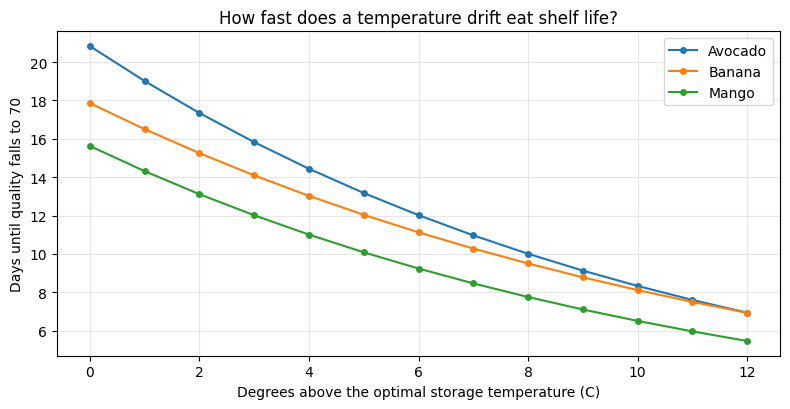

commodity,Avocado,Banana,Mango
+0 C,20.8,17.9,15.6
+4 C,14.4,13.0,11.0
+8 C,10.0,9.5,7.8
+12 C,6.9,6.9,5.5


In [8]:
curves = pd.read_sql(f'''
    WITH RECURSIVE offs(offset_c) AS (
        SELECT 0 UNION ALL SELECT offset_c + 1 FROM offs WHERE offset_c < 12
    )
    SELECT p.commodity, o.offset_c,
           p.opt_temp_c + o.offset_c AS temp_c,
           p.base_loss_pts_hr * PYPOW(p.q10, o.offset_c / 10.0) AS loss_rate_pts_hr,
           (100.0 - {QUALITY_THRESHOLD}) / (p.base_loss_pts_hr * PYPOW(p.q10, o.offset_c / 10.0) * 24.0) AS shelf_life_days
    FROM ref_commodity_params p CROSS JOIN offs o
    ORDER BY p.commodity, o.offset_c
''', conn)

fig, ax = plt.subplots(figsize=(8, 4.2))
for commodity, g in curves.groupby("commodity"):
    ax.plot(g.offset_c, g.shelf_life_days, marker="o", ms=4, label=commodity)
ax.set_xlabel("Degrees above the optimal storage temperature (C)")
ax.set_ylabel(f"Days until quality falls to {QUALITY_THRESHOLD}")
ax.set_title("How fast does a temperature drift eat shelf life?")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

pivot = curves[curves.offset_c.isin([0, 4, 8, 12])].pivot(index="offset_c", columns="commodity", values="shelf_life_days").round(1)
pivot.index = [f"+{i} C" for i in pivot.index]
pivot

## 9. Run the stream: micro-batches, models and a live alert feed

Now the pipeline runs end to end. For each simulated hour, the producer publishes sensor events to the
topic. Every 3 hours the consumer polls a micro-batch, lands it in the warehouse, commits its offsets, and
the SQL models rebuild. An alert engine then checks the fresh marts and prints **new** alerts as they
appear:

| Alert | Fires when |
|---|---|
| `TEMP_DRIFT` | 3-hour mean temperature is more than 2 C from the setpoint |
| `HUMIDITY_SPIKE` | 3-hour mean humidity is more than 3 points outside the optimal band |
| `VIBRATION` | 3-hour mean vibration exceeds 1.5 g |
| `SPOILAGE_RATE` | The current loss rate is at least 1.5x the healthy baseline |
| `REROUTE_RECOMMENDED` | Forecast revenue at the secondary market beats the primary by more than the minimum arbitrage |

The reroute forecast assumes the **current loss rate persists** until arrival. When a drift is still
growing, that is a conservative estimate.

In [9]:
alerts, resolved, active = [], [], set()

def evaluate_alerts(conn):
    health = pd.read_sql("SELECT * FROM mart_container_health", conn)
    arb = pd.read_sql("SELECT container_id, arbitrage_usd, fq_primary, fq_secondary, recommendation "
                      "FROM mart_spoilage_arbitrage", conn)
    df = health.merge(arb, on="container_id")
    for r in df.itertuples():
        checks = {
            "TEMP_DRIFT": (abs(r.temp_dev_c) > 2.0, f"3h mean temperature {r.temp_dev_c:+.1f} C vs setpoint"),
            "HUMIDITY_SPIKE": (r.rh_out_of_band_pct > 3.0, f"humidity {r.rh_3h:.1f}% is {r.rh_out_of_band_pct:.1f} pts outside band"),
            "VIBRATION": (r.vib_3h > 1.5, f"3h mean vibration {r.vib_3h:.2f} g"),
            "SPOILAGE_RATE": (r.stress_ratio >= 1.5, f"spoiling {r.stress_ratio:.1f}x faster than baseline"),
            "REROUTE_RECOMMENDED": (r.recommendation == "REROUTE",
                                    f"arbitrage ${r.arbitrage_usd:,.0f} (forecast quality {r.fq_primary:.0f} at primary vs {r.fq_secondary:.0f} at secondary)"),
        }
        for atype, (hit, detail) in checks.items():
            key = (r.container_id, atype)
            if hit and key not in active:
                active.add(key)
                alerts.append(dict(alert_ts=r.as_of_ts, container_id=r.container_id,
                                   commodity=r.commodity, alert_type=atype, detail=detail))
                print(f"[{r.as_of_ts}] Container {r.container_id} ({r.commodity}) {atype}: {detail}")
            elif not hit and key in active:
                active.discard(key)
                resolved.append(dict(resolved_ts=r.as_of_ts, container_id=r.container_id, alert_type=atype))
                print(f"[{r.as_of_ts}] Container {r.container_id} ({r.commodity}) {atype}: resolved")

batch_id = 0
for hour in range(STREAM_HOURS):
    for ev in produce_hour(hour):
        topic.send(ev["container_id"], ev)                 # producer publishes
    if (hour + 1) % BATCH_HOURS == 0:                      # consumer runs a micro-batch
        records = consumer.poll()
        batch_id += 1
        land_batch(records, batch_id)                      # 1. land raw events in the warehouse
        consumer.commit(records)                           # 2. commit offsets only after landing
        run_models(conn)                                   # 3. rebuild the SQL models
        evaluate_alerts(conn)                              # 4. check alert rules

alerts_df = pd.DataFrame(alerts)
alerts_df.to_sql("alerts_log", conn, index=False, if_exists="replace")
resolved_df = pd.DataFrame(resolved, columns=["resolved_ts", "container_id", "alert_type"])
resolved_df.to_sql("alerts_resolved", conn, index=False, if_exists="replace")
print(f"\nStream complete: {batch_id} micro-batches, {len(alerts_df)} alerts raised, {len(resolved_df)} resolved.")

[2026-10-02 11:45:00] Container D (Avocado) HUMIDITY_SPIKE: humidity 98.5% is 3.5 pts outside band
[2026-10-02 11:45:00] Container D (Avocado) SPOILAGE_RATE: spoiling 1.6x faster than baseline
[2026-10-02 11:45:00] Container D (Avocado) REROUTE_RECOMMENDED: arbitrage $4,828 (forecast quality 68 at primary vs 80 at secondary)


[2026-10-04 14:45:00] Container A (Avocado) TEMP_DRIFT: 3h mean temperature +2.0 C vs setpoint


[2026-10-05 08:45:00] Container A (Avocado) SPOILAGE_RATE: spoiling 1.5x faster than baseline
[2026-10-05 08:45:00] Container A (Avocado) REROUTE_RECOMMENDED: arbitrage $2,229 (forecast quality 72 at primary vs 83 at secondary)
[2026-10-05 11:45:00] Container C (Mango) VIBRATION: 3h mean vibration 2.09 g
[2026-10-05 11:45:00] Container C (Mango) SPOILAGE_RATE: spoiling 2.3x faster than baseline
[2026-10-05 11:45:00] Container C (Mango) REROUTE_RECOMMENDED: arbitrage $7,286 (forecast quality 57 at primary vs 73 at secondary)


[2026-10-06 05:45:00] Container C (Mango) VIBRATION: resolved
[2026-10-06 08:45:00] Container C (Mango) SPOILAGE_RATE: resolved
[2026-10-06 08:45:00] Container C (Mango) REROUTE_RECOMMENDED: resolved



Stream complete: 48 micro-batches, 9 alerts raised, 3 resolved.


## 10. Data quality: what did the pipeline have to clean?

A short audit of the raw layer against the staged layer, so we know the faults were handled rather than
silently ignored.

In [10]:
raw_n = conn.execute("SELECT COUNT(*) FROM raw_sensor_events").fetchone()[0]
stg_n = conn.execute("SELECT COUNT(*) FROM stg_sensor_events").fetchone()[0]
distinct_n = conn.execute("SELECT COUNT(*) FROM (SELECT DISTINCT container_id, event_ts FROM raw_sensor_events)").fetchone()[0]
nulls_n = conn.execute('''SELECT COUNT(*) FROM (SELECT DISTINCT container_id, event_ts FROM raw_sensor_events
                          WHERE temp_c IS NULL OR humidity_pct IS NULL OR vibration_g IS NULL)''').fetchone()[0]
glitch_n = conn.execute("SELECT COUNT(*) FROM raw_sensor_events WHERE temp_c < -30 OR temp_c > 60").fetchone()[0]
expected_n = STREAM_HOURS * READINGS_PER_HOUR * len(containers)

dq = pd.DataFrame({
    "check": ["Events expected (6 containers x 15-min readings)", "Raw events landed", "Duplicate deliveries removed",
              "Readings with a null sensor value", "Impossible readings (firmware glitches)", "Clean readings used downstream",
              "Coverage of expected readings"],
    "value": [expected_n, raw_n, raw_n - distinct_n, nulls_n, glitch_n, stg_n, f"{stg_n / expected_n:.1%}"],
})
dq

,check,value
0,Events expected (6 containers x 15-min readings),3456
1,Raw events landed,3498
2,Duplicate deliveries removed,42
3,Readings with a null sensor value,57
4,Impossible readings (firmware glitches),22
5,Clean readings used downstream,3377
6,Coverage of expected readings,97.7%


## 11. The AtmoSync dashboard

Everything below is read from the warehouse's **mart tables**, which is how a BI tool would consume them.
The dashboard shows the fleet at the moment the stream ends (day 6 at sea).

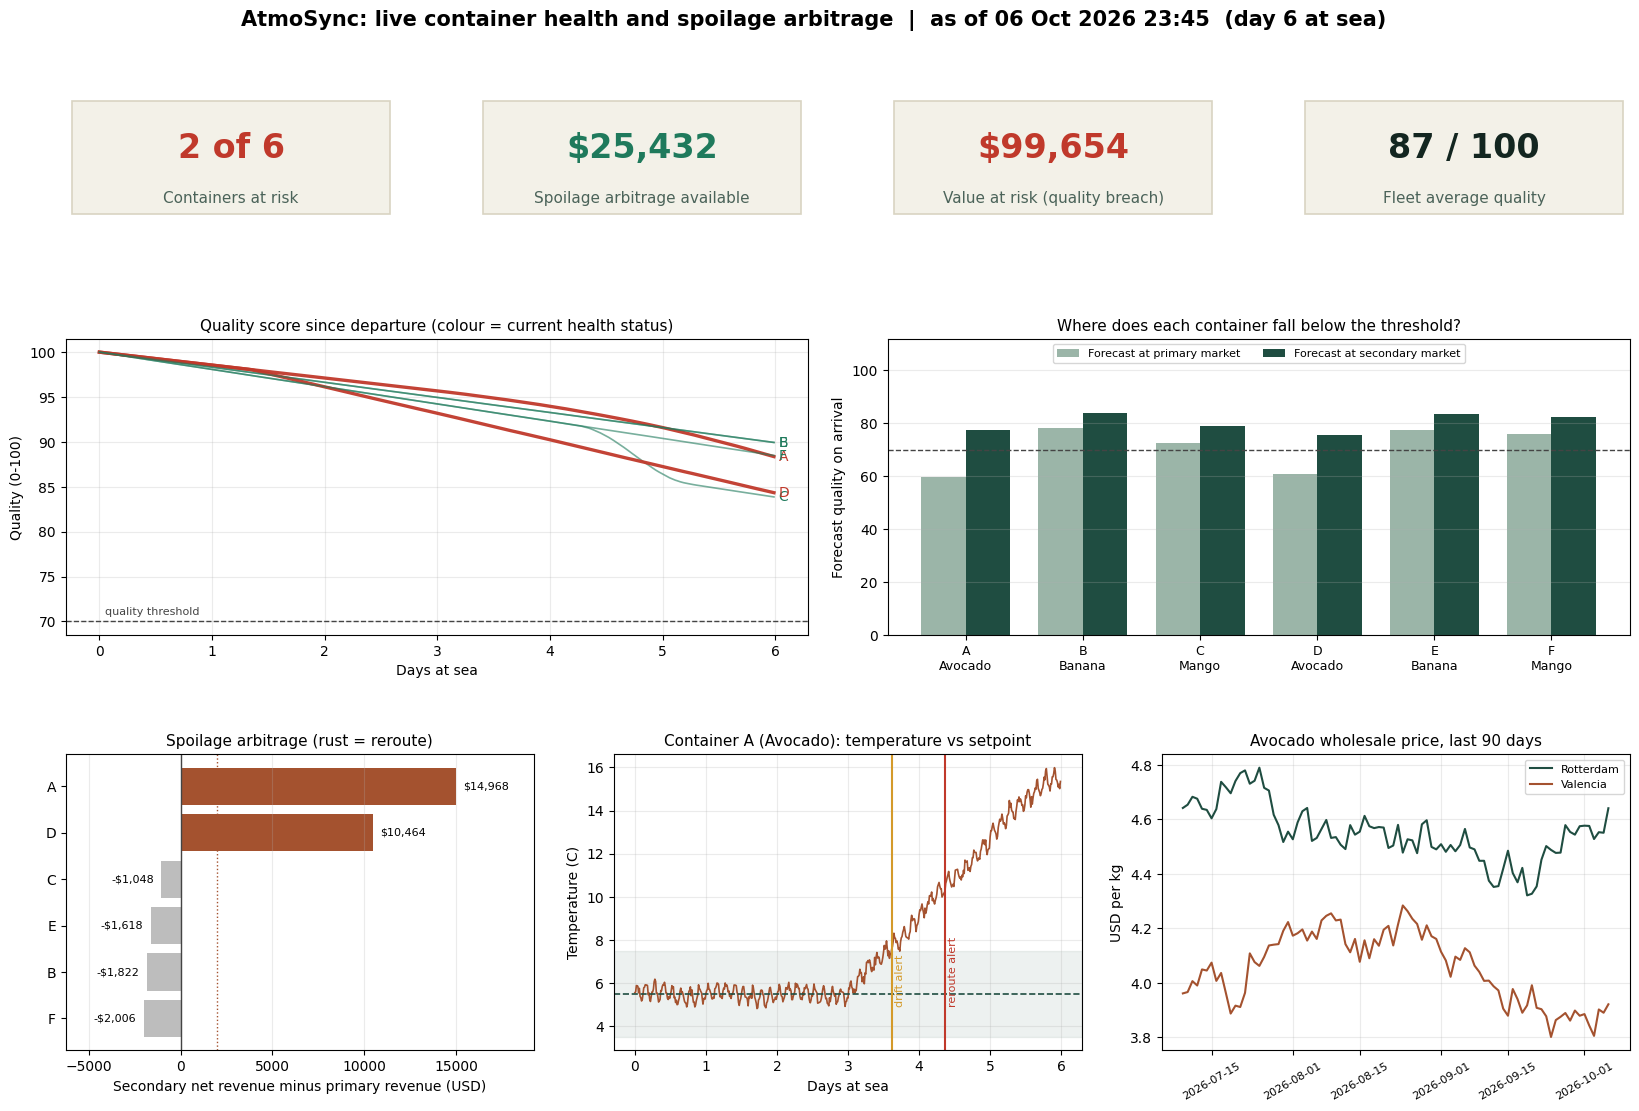

In [11]:
STATUS_COLOUR = {"HEALTHY": "#1f7a5c", "WATCH": "#d49a2a", "CRITICAL": "#c0392b"}

def render_dashboard(conn, alerts_df):
    health = pd.read_sql("SELECT * FROM mart_container_health", conn)
    arb = pd.read_sql("SELECT * FROM mart_spoilage_arbitrage", conn)
    fq = pd.read_sql("SELECT container_id, event_ts, temp_c, quality_score FROM fct_quality", conn)
    fq["hours"] = (pd.to_datetime(fq["event_ts"]) - VOYAGE_START).dt.total_seconds() / 3600
    status = health.set_index("container_id")["health_status"].to_dict()

    focus = arb.sort_values("arbitrage_usd", ascending=False).iloc[0]       # the container to spotlight
    fcid = focus.container_id
    setpoint = P[focus.commodity]["opt_temp_c"]

    fig = plt.figure(figsize=(17, 11.5))
    gs = GridSpec(3, 12, figure=fig, height_ratios=[0.5, 1.2, 1.2], hspace=0.5, wspace=1.4,
                  top=0.9, bottom=0.07, left=0.06, right=0.98)

    # ---- KPI tiles ----
    n_risk = int((health.health_status != "HEALTHY").sum())
    opportunity = arb.loc[arb.recommendation == "REROUTE", "arbitrage_usd"].sum()
    var = arb.loc[arb.breaches_threshold == 1, "value_at_risk_usd"].sum()
    tiles = [
        ("Containers at risk", f"{n_risk} of {len(health)}", "#c0392b" if n_risk else "#1f7a5c"),
        ("Spoilage arbitrage available", usd(opportunity), "#1f7a5c"),
        ("Value at risk (quality breach)", usd(var), "#c0392b" if var else "#1f7a5c"),
        ("Fleet average quality", f"{health.quality_score.mean():.0f} / 100", "#132620"),
    ]
    for i, (label, value, colour) in enumerate(tiles):
        ax = fig.add_subplot(gs[0, i * 3:(i + 1) * 3])
        ax.add_patch(Rectangle((0.02, 0.04), 0.96, 0.92, transform=ax.transAxes, facecolor="#f3f1e8", edgecolor="#d9d4c2", lw=1.2))
        ax.text(0.5, 0.58, value, ha="center", va="center", fontsize=24, color=colour, fontweight="bold")
        ax.text(0.5, 0.17, label, ha="center", va="center", fontsize=11, color="#4b6359")
        ax.axis("off")

    # ---- quality curves ----
    ax = fig.add_subplot(gs[1, 0:6])
    for cid, g in fq.groupby("container_id"):
        s = status[cid]
        ax.plot(g.hours / 24, g.quality_score, color=STATUS_COLOUR[s], lw=2.4 if s != "HEALTHY" else 1.2,
                alpha=0.95 if s != "HEALTHY" else 0.6)
        ax.text(g.hours.max() / 24 + 0.04, g.quality_score.iloc[-1], cid, color=STATUS_COLOUR[s], fontsize=10, va="center")
    ax.axhline(QUALITY_THRESHOLD, color="#444", ls="--", lw=1)
    ax.text(0.05, QUALITY_THRESHOLD + 0.8, "quality threshold", fontsize=8, color="#444")
    ax.set_title("Quality score since departure (colour = current health status)", fontsize=11)
    ax.set_xlabel("Days at sea"); ax.set_ylabel("Quality (0-100)"); ax.grid(alpha=0.25)

    # ---- forecast quality on arrival ----
    ax = fig.add_subplot(gs[1, 6:12])
    x = np.arange(len(arb)); w = 0.38
    ax.bar(x - w / 2, arb.fq_primary, w, label="Forecast at primary market", color="#9bb5a8")
    ax.bar(x + w / 2, arb.fq_secondary, w, label="Forecast at secondary market", color="#1f4d41")
    ax.axhline(QUALITY_THRESHOLD, color="#444", ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels([f"{c}\n{m}" for c, m in zip(arb.container_id, arb.commodity)], fontsize=9)
    ax.set_ylim(0, 112); ax.set_ylabel("Forecast quality on arrival")
    ax.set_title("Where does each container fall below the threshold?", fontsize=11)
    ax.legend(fontsize=8, loc="upper center", ncol=2); ax.grid(axis="y", alpha=0.25)

    # ---- arbitrage by container ----
    ax = fig.add_subplot(gs[2, 0:4])
    a = arb.sort_values("arbitrage_usd")
    ax.barh(a.container_id, a.arbitrage_usd, color=["#a4522f" if r == "REROUTE" else "#bdbdbd" for r in a.recommendation])
    ax.axvline(0, color="#444", lw=1); ax.axvline(MIN_ARBITRAGE_USD, color="#a4522f", ls=":", lw=1)
    for i, v in enumerate(a.arbitrage_usd):
        ax.text(v + (400 if v >= 0 else -400), i, usd(v), va="center", ha="left" if v >= 0 else "right", fontsize=8)
    ax.set_title("Spoilage arbitrage (rust = reroute)", fontsize=11)
    ax.set_xlabel("Secondary net revenue minus primary revenue (USD)")
    ax.margins(x=0.25); ax.grid(axis="x", alpha=0.25)

    # ---- focus container temperature ----
    ax = fig.add_subplot(gs[2, 4:8])
    g = fq[fq.container_id == fcid]
    ax.plot(g.hours / 24, g.temp_c, color="#a4522f", lw=1.2)
    ax.axhline(setpoint, color="#1f4d41", ls="--", lw=1.2)
    ax.axhspan(setpoint - 2, setpoint + 2, color="#1f4d41", alpha=0.08)
    for atype, colour, label in [("TEMP_DRIFT", "#d49a2a", "drift alert"), ("REROUTE_RECOMMENDED", "#c0392b", "reroute alert")]:
        hit = alerts_df[(alerts_df.container_id == fcid) & (alerts_df.alert_type == atype)]
        if len(hit):
            hx = (pd.to_datetime(hit.alert_ts.iloc[0]) - VOYAGE_START).total_seconds() / 86400
            ax.axvline(hx, color=colour, lw=1.5); ax.text(hx + 0.04, g.temp_c.min() + 0.2, label, rotation=90, fontsize=8, color=colour)
    ax.set_title(f"Container {fcid} ({focus.commodity}): temperature vs setpoint", fontsize=11)
    ax.set_xlabel("Days at sea"); ax.set_ylabel("Temperature (C)"); ax.grid(alpha=0.25)

    # ---- price history ----
    ax = fig.add_subplot(gs[2, 8:12])
    pr = pd.read_sql("SELECT * FROM raw_commodity_prices WHERE commodity = ?", conn, params=(focus.commodity,), parse_dates=["price_date"])
    for market, colour in [(focus.primary_market, "#1f4d41"), (focus.secondary_market, "#a4522f")]:
        s = pr[pr.market == market]
        ax.plot(s.price_date, s.price_usd_per_kg, color=colour, label=market, lw=1.5)
    ax.set_title(f"{focus.commodity} wholesale price, last 90 days", fontsize=11)
    ax.set_ylabel("USD per kg"); ax.legend(fontsize=8); ax.grid(alpha=0.25)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)

    fig.suptitle("AtmoSync: live container health and spoilage arbitrage  |  as of " +
                 pd.to_datetime(health.as_of_ts.max()).strftime("%d %b %Y %H:%M") + "  (day 6 at sea)",
                 fontsize=15, fontweight="bold", y=0.975)
    plt.show()
    return health, arb

health, arb = render_dashboard(conn, alerts_df)

**How to read the tiles.** *Containers at risk* counts any container whose status is WATCH or CRITICAL.
*Spoilage arbitrage available* adds up the net gain from every recommended reroute. *Value at risk* is the revenue
that containers forecast to fall below the quality threshold would lose at the primary market, compared with
arriving in perfect condition. Only part of that can be recovered by rerouting, which is the arbitrage.

### Container health and reroute decisions

In [12]:
display(health[["container_id", "commodity", "quality_score", "temp_dev_c", "rh_out_of_band_pct",
                "vib_3h", "stress_ratio", "health_status"]].rename(columns={
    "temp_dev_c": "temp_vs_setpoint_c", "rh_out_of_band_pct": "humidity_outside_band", "vib_3h": "vibration_g_3h"}))

decision = arb[["container_id", "commodity", "primary_market", "secondary_market", "quality_now",
                "fq_primary", "fq_secondary", "revenue_primary", "revenue_secondary_net",
                "arbitrage_usd", "recommendation"]].sort_values("arbitrage_usd", ascending=False)
decision

,container_id,commodity,quality_score,temp_vs_setpoint_c,humidity_outside_band,vibration_g_3h,stress_ratio,health_status
0,A,Avocado,88.4,9.96,0.0,0.45,2.48,CRITICAL
1,B,Banana,89.9,-0.04,0.0,0.47,0.99,HEALTHY
2,C,Mango,83.9,-0.04,0.0,0.49,0.99,HEALTHY
3,D,Avocado,84.3,-0.05,3.5,0.46,2.04,CRITICAL
4,E,Banana,89.9,-0.12,0.0,0.38,0.99,HEALTHY
5,F,Mango,88.5,-0.00,0.0,0.50,0.99,HEALTHY


,container_id,commodity,primary_market,secondary_market,quality_now,fq_primary,fq_secondary,revenue_primary,revenue_secondary_net,arbitrage_usd,recommendation
0,A,Avocado,Rotterdam,Valencia,88.4,59.8,77.6,40834.0,55802.0,14968.0,REROUTE
3,D,Avocado,Rotterdam,Valencia,84.3,60.8,75.5,42374.0,52838.0,10464.0,REROUTE
2,C,Mango,Antwerp,Algeciras,83.9,72.4,79.1,34668.0,33620.0,-1048.0,STAY COURSE
4,E,Banana,Hamburg,Lisbon,89.9,77.4,83.7,19657.0,18039.0,-1618.0,STAY COURSE
1,B,Banana,Hamburg,Lisbon,89.9,78.2,84.0,20005.0,18183.0,-1822.0,STAY COURSE
5,F,Mango,Antwerp,Algeciras,88.5,76.1,82.3,37981.0,35975.0,-2006.0,STAY COURSE


## 12. Deep dive: the reroute decision for the top opportunity

The trader's view of the container with the largest arbitrage. The left chart projects quality forward
at the current loss rate. Staying on course reaches the primary market after the cargo has degraded further.
Rerouting lands the goods earlier, at a higher quality, at a lower price per kilogram and with an extra
diversion cost. The right chart shows how those trade-offs net out.

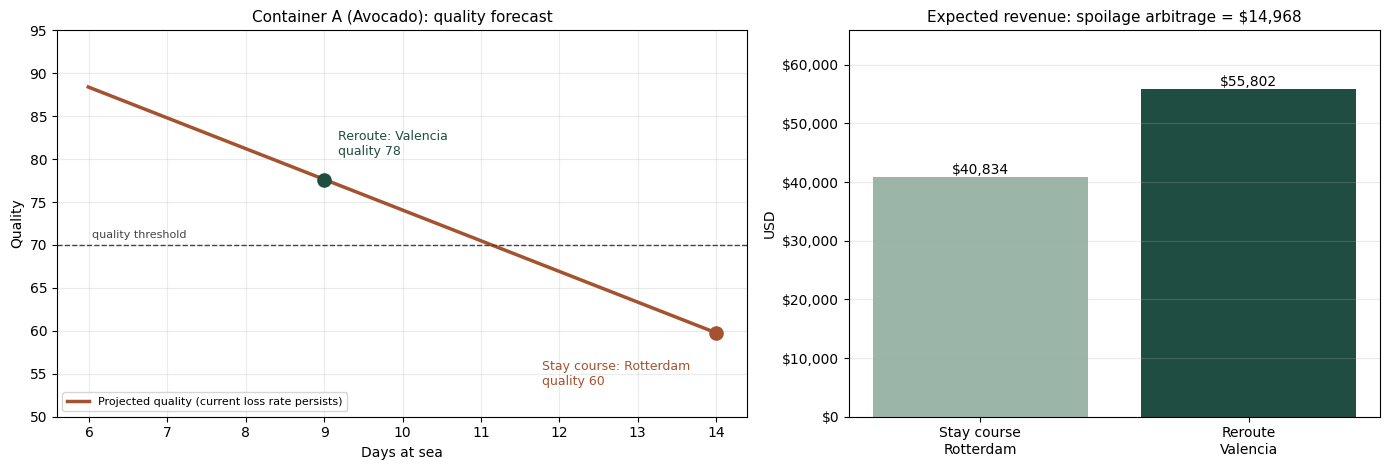

,Stay course (Rotterdam),Reroute (Valencia)
,,
Forecast quality on arrival,59.8,77.6
Price per kg (7-day average),$4.57,$3.88
Price multiplier at that quality,0.45,0.76
Gross revenue,"$40,834","$58,802"
Reroute cost,$0,"-$3,000"
Net revenue,"$40,834","$55,802"


In [13]:
top = arb.sort_values("arbitrage_usd", ascending=False).iloc[0]
hrow = health[health.container_id == top.container_id].iloc[0]
now_hr = (pd.to_datetime(hrow.as_of_ts) - VOYAGE_START).total_seconds() / 3600
ce = containers[containers.container_id == top.container_id].iloc[0]

t = np.linspace(now_hr, ce.primary_eta_hr, 200)
traj = np.maximum(0, hrow.quality_score - hrow.loss_rate_pts_hr * (t - now_hr))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.plot(t / 24, traj, color="#a4522f", lw=2.5, label="Projected quality (current loss rate persists)")
ax.axhline(QUALITY_THRESHOLD, color="#444", ls="--", lw=1)
ax.scatter([ce.secondary_eta_hr / 24], [top.fq_secondary], s=90, color="#1f4d41", zorder=5)
ax.scatter([ce.primary_eta_hr / 24], [top.fq_primary], s=90, color="#a4522f", zorder=5)
ax.annotate(f"Reroute: {top.secondary_market}\nquality {top.fq_secondary:.0f}", (ce.secondary_eta_hr / 24, top.fq_secondary),
            textcoords="offset points", xytext=(10, 18), fontsize=9, color="#1f4d41")
ax.annotate(f"Stay course: {top.primary_market}\nquality {top.fq_primary:.0f}", (ce.primary_eta_hr / 24, top.fq_primary),
            textcoords="offset points", xytext=(-125, -38), fontsize=9, color="#a4522f")
ax.set_xlabel("Days at sea"); ax.set_ylabel("Quality"); ax.set_ylim(50, 95)
ax.text(now_hr / 24 + 0.05, QUALITY_THRESHOLD + 0.8, "quality threshold", fontsize=8, color="#444")
ax.set_title(f"Container {top.container_id} ({top.commodity}): quality forecast", fontsize=11)
ax.grid(alpha=0.25); ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
vals = [top.revenue_primary, top.revenue_secondary_net]
bars = ax.bar([f"Stay course\n{top.primary_market}", f"Reroute\n{top.secondary_market}"], vals, color=["#9bb5a8", "#1f4d41"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v, usd(v), ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, max(vals) * 1.18)
ax.set_title(f"Expected revenue: spoilage arbitrage = {usd(top.arbitrage_usd)}", fontsize=11)
ax.set_ylabel("USD"); ax.grid(axis="y", alpha=0.25)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
plt.tight_layout(); plt.show()

detail = pd.DataFrame({
    "": ["Forecast quality on arrival", "Price per kg (7-day average)", "Price multiplier at that quality",
         "Gross revenue", "Reroute cost", "Net revenue"],
    f"Stay course ({top.primary_market})": [f"{top.fq_primary:.1f}", f"${top.price_primary:.2f}", f"{price_mult(top.fq_primary):.2f}",
                                           f"${top.revenue_primary:,.0f}", "$0", f"${top.revenue_primary:,.0f}"],
    f"Reroute ({top.secondary_market})": [f"{top.fq_secondary:.1f}", f"${top.price_secondary:.2f}", f"{price_mult(top.fq_secondary):.2f}",
                                         f"${top.revenue_secondary_net + top.reroute_cost_usd:,.0f}", f"-${top.reroute_cost_usd:,.0f}",
                                         f"${top.revenue_secondary_net:,.0f}"],
}).set_index("")
detail

## 13. Did the pipeline catch the incidents? (validation)

Because the incidents were injected, we know exactly when each one started, so we can measure
**detection lag**: the hours between the fault starting and the alert firing. The pipeline checks in
every 3 hours and uses 3-hour averages, so some lag is expected. We also check for **false alarms**
on the three healthy containers.

In [14]:
onsets = {"A": ("TEMP_DRIFT", 72, "cooling drift"), "D": ("HUMIDITY_SPIKE", 30, "humidity spike"), "C": ("VIBRATION", 96, "rough handling")}
rows = []
for cid, (atype, onset_hr, label) in onsets.items():
    hit = alerts_df[(alerts_df.container_id == cid) & (alerts_df.alert_type == atype)]
    if len(hit):
        alert_hr = (pd.to_datetime(hit.alert_ts.iloc[0]) - VOYAGE_START).total_seconds() / 3600
        rows.append((cid, label, onset_hr, round(alert_hr, 1), round(alert_hr - onset_hr, 1)))
    else:
        rows.append((cid, label, onset_hr, None, None))
lag = pd.DataFrame(rows, columns=["container", "incident", "onset_hour", "first_alert_hour", "detection_lag_hours"])
display(lag)

healthy = [c for c in containers.container_id if c not in onsets]
false_alarms = alerts_df[alerts_df.container_id.isin(healthy)]
print(f"Healthy containers {healthy}: {len(false_alarms)} alerts raised (false alarms).")

raised = alerts_df[alerts_df.alert_type == "REROUTE_RECOMMENDED"]
current = set(arb.loc[arb.recommendation == "REROUTE", "container_id"])
withdrawn = sorted(set(raised.container_id) - current)
print("\nReroute recommendations raised during the voyage:", sorted(raised.container_id.unique()))
print("Still recommended at day 6:", sorted(current))
for cid in withdrawn:
    r_ts = raised[raised.container_id == cid].alert_ts.iloc[0]
    w = resolved_df[(resolved_df.container_id == cid) & (resolved_df.alert_type == "REROUTE_RECOMMENDED")]
    when = w.resolved_ts.iloc[0] if len(w) else "later"
    print(f"Container {cid}: reroute raised {r_ts}, withdrawn {when}. The disturbance ended and the loss rate "
          f"returned to normal, so the forecast recovered. This is the persistence forecast reacting to a transient event.")

,container,incident,onset_hour,first_alert_hour,detection_lag_hours
0,A,cooling drift,72,86.8,14.8
1,D,humidity spike,30,35.8,5.8
2,C,rough handling,96,107.8,11.8


Healthy containers ['B', 'E', 'F']: 0 alerts raised (false alarms).

Reroute recommendations raised during the voyage: ['A', 'C', 'D']
Still recommended at day 6: ['A', 'D']
Container C: reroute raised 2026-10-05 11:45:00, withdrawn 2026-10-06 08:45:00. The disturbance ended and the loss rate returned to normal, so the forecast recovered. This is the persistence forecast reacting to a transient event.


## 14. Findings

In [15]:
rr = arb[arb.recommendation == "REROUTE"].sort_values("arbitrage_usd", ascending=False)
print(f"Containers flagged for reroute: {len(rr)} of {len(arb)}")
for r in rr.itertuples():
    print(f"  Container {r.container_id} ({r.commodity}): reroute {r.primary_market} -> {r.secondary_market} "
          f"protects about ${r.arbitrage_usd:,.0f} (quality on arrival {r.fq_primary:.0f} -> {r.fq_secondary:.0f})")

stay = arb[arb.recommendation == "STAY COURSE"]
print(f"\nContainers to leave on course: {', '.join(stay.container_id)}")
print(f"Total spoilage arbitrage available: ${rr.arbitrage_usd.sum():,.0f}")

Containers flagged for reroute: 2 of 6
  Container A (Avocado): reroute Rotterdam -> Valencia protects about $14,968 (quality on arrival 60 -> 78)
  Container D (Avocado): reroute Rotterdam -> Valencia protects about $10,464 (quality on arrival 61 -> 76)

Containers to leave on course: B, C, E, F
Total spoilage arbitrage available: $25,432


**Reading the result.** A drifting temperature does more than shorten shelf life: it moves the
*arrival quality* of a shipment across a price cliff. A shipment that would reach its primary market
below the quality threshold loses a large share of its value, while a nearer market sees it earlier
and in better shape. The arbitrage is the net gain from diverting, after the lower price and the
diversion cost, and it is only worth acting on when it clears the minimum.

Containers whose sensors were disturbed but have since recovered, or whose forecast stays above
the threshold, are correctly left alone. Reroute alerts that do not fire matter as much as those that do.

### Limitations
- **Simulated data.** Sensors, prices and cargo are generated, so the numbers show the method rather than
  real market behaviour. The spoilage parameters are plausible but not calibrated to a published shelf-life study.
- **Persistence forecast.** The forecast assumes today's loss rate continues. That under-estimates a drift that is
  still growing, and over-estimates one that has stabilised or been repaired. A production model would
  forecast the sensor trend.
- **One-sided temperature model.** Chilling injury (too cold) is not modelled, and there is no ripening-stage effect.
- **Static prices and routes.** Prices use a trailing 7-day average and the ETAs are fixed. Real decisions need live
  quotes, port congestion and diversion feasibility.
- **Full-refresh models.** Each batch rebuilds every table. With millions of events you would build the models
  incrementally.

### Next steps
- Replace the simulated stream with a real broker topic and the SQLite file with a cloud warehouse; the SQL models
  carry over with small dialect changes.
- Add a trend-based forecast (for example, an exponentially weighted loss rate) instead of persistence.
- Calibrate the spoilage parameters and price curve with post-harvest research and real sale data.
- Add a "what-if" panel that varies the minimum arbitrage threshold and the diversion cost.